In [1]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [2]:
model = YOLO('yolov8n.pt')
classNames = model.names
len(classNames)

80

bus 0.87 (22, 231, 805, 756)
person 0.87 (48, 398, 245, 902)
person 0.85 (669, 392, 809, 877)
person 0.83 (221, 405, 344, 857)


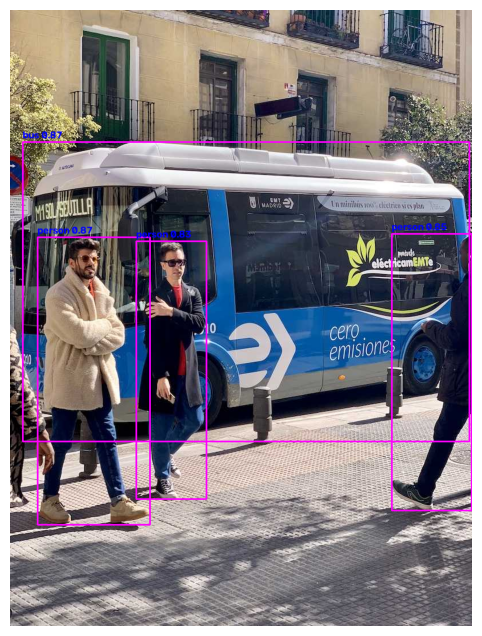

In [3]:
img = cv2.imread('bus.jpg')
results = model(img, conf=0.4, verbose=False)[0]

for box in results.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    conf = float(box.conf[0])
    name = classNames[int(box.cls[0])]
    print(name, round(conf, 2), (x1, y1, x2, y2))
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 255), 2)
    cv2.putText(img, f'{name} {conf:.2f}', (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

In [4]:
os.makedirs('output', exist_ok=True)
cv2.imwrite('output/task1_yolo.png', cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

True

In [5]:
webcam = False

if webcam:
    cap = cv2.VideoCapture(0)
    cap.set(3, 640)
    cap.set(4, 480)

    while True:
        success, frame = cap.read()
        for box in model(frame, conf=0.4, verbose=False)[0].boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            name = classNames[int(box.cls[0])]
            cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 0, 255), 2)
            cv2.putText(frame, f'{name} {float(box.conf[0]):.2f}', (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

        cv2.imshow('Webcam', frame)
        if cv2.waitKey(1) == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

Used YOLOv8n from ultralytics, pretrained on COCO, with a confidence threshold of 0.4. COCO already has the usual lab things (laptop, keyboard, mouse, cell phone, bottle, book, chair, tv) so no training was needed. The webcam loop is the same code run on every frame, press q to quit. Only tested on a still image here (bus.jpg), not on a live camera.